# Objective 2 - Customer segmentation from purchases

> *To implement an intelligent analytics module that performs customer segmentation and purchase
> behaviour prediction to support business decision-making and marketing strategies.*

`03_segmentation.ipynb` groups the **products**. This notebook groups the **purchases**, so that each
group describes a kind of customer need: what was bought, at what price and in what quantity.

## Why purchases and not people

The receipts carry no customer identifier, so nothing links two receipts to the same buyer. Each
receipt is treated as **one buyer's purchase**. The workbook describes itself as an
*individual receipt dataset*, and every receipt holds a single product line.

That also settles what the groups can honestly be called. A gaming laptop might be bought by a
gamer or by a student, and a PC with a graphics card might go to an office. From one receipt we
cannot tell who the person was, only **what kind of purchase it was**. The segments below are
therefore *purchase segments*: "a gaming purchase", not "a gamer".

True customer segments need the customer, and the online shop has that. Every account picks
Student, Gamer or Enterprise at sign-up, so purchases made through the website carry a real label.
Those labels are how these purchase segments get checked once the beta testers have bought
(Objective 1's data).

**Type of learning:** unsupervised (K-Means clustering). Nothing is labelled in advance; the
algorithm finds the groups and they are named afterwards from what they contain.

**Data agreement:** only product, price, quantity and date are used. No customer personal data,
supplier detail, cost price or margin appears anywhere in this notebook.

In [1]:
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

lines = pd.read_csv("data/processed/sales_lines_products.csv", parse_dates=["date"])
print(f"{len(lines):,} product receipts, {lines.date.min():%Y-%m-%d} to {lines.date.max():%Y-%m-%d}")
print("product lines per receipt:", lines.groupby("saleId").size().max())

7,939 product receipts, 2022-01-01 to 2026-08-31
product lines per receipt: 1


## Describing each purchase

K-Means needs numbers. A purchase is described by six features, each a **fact about what was bought**,
never a guess about the buyer:

| Feature | What it captures | Source |
|---|---|---|
| `price` | how much one unit cost (log scale) | `unitPrice` |
| `quantity` | how many units on the receipt (log scale): bulk buying | `quantity` |
| `gpu_tier` | graphics power, 0-3, for graphics cards and complete rigs | the GPU's model name |
| `gaming_grade` | the product is built or sold for gaming | product name and specification |
| `business_grade` | the product is built or sold for business | product name and sub-category |
| `whole_system` | a complete computer (rig or laptop) rather than a part or accessory | category |

**Why category itself is not a feature.** One-hot categories would make K-Means rebuild the
category list and call it a finding. These features describe the purchase across categories:
a gaming mouse and a gaming rig share `gaming_grade`; a laser printer and a ThinkPad share
`business_grade`.

**GPU tiers.** 0 = no graphics card or a display-only card (GT 710); 1 = entry gaming (RTX 3050, RTX 5050);
2 = mid-range (RTX 3060, RTX 5060 Ti, RX 9060 XT); 3 = high end (RTX 3080, RTX 3090, RTX 5090).

In [2]:
def gpu_tier(name):
    if not isinstance(name, str):          return 0
    if re.search(r"GT 710", name, re.I):   return 0
    if re.search(r"3050|5050", name):      return 1
    if re.search(r"3060|5060|9060", name): return 2
    if re.search(r"3080|3090|5090", name): return 3
    return 0

# A graphics card bought on its own carries its tier in its own name; a rig carries it in its gpu column.
gpu_name = np.where(lines.subcategory == "Graphics Card", lines.itemName, lines.gpu)
lines["gpu_tier"] = [gpu_tier(g) for g in gpu_name]

# Gaming-grade: gaming in the name or sub-category, a gaming product line (ROG, Nitro, MAG, Razer, HyperX),
# an X3D gaming CPU, a refresh rate of 144 Hz or more, RGB lighting, or a mid/high-end GPU.
GAMING = r"gaming|\brog\b|nitro|\bmag\b|razer|hyperx|x3d|argb|\b(?:1[4-9]\d|2\d\d)hz"
lines["gaming_grade"] = (lines.itemName.str.contains(GAMING, case=False, regex=True)
                         | lines.subcategory.str.contains("gaming", case=False)
                         | lines.subcategory.isin(["ARGB Lighting", "Mouse Pad"])
                         | (lines.gpu_tier >= 2)).astype(int)

# Business-grade: business product lines and office machines, and the kit an office buys.
BUSINESS = r"thinkpad|dragonfly|workstation|office|business"
lines["business_grade"] = (lines.itemName.str.contains(BUSINESS, case=False, regex=True)
                           | lines.subcategory.str.contains(BUSINESS, case=False, regex=True)
                           | lines.subcategory.isin(["Docking Station", "UPS", "Laser Printer",
                                                     "Laser", "Multifunction Printer"])).astype(int)

lines["whole_system"] = lines.category.isin(["Complete PC Rig", "Laptop"]).astype(int)

print("purchases that are both gaming- and business-grade:",
      int((lines.gaming_grade & lines.business_grade).sum()),
      "(workstations with a high-end GPU, for example)")
display(pd.crosstab(lines.gaming_grade, lines.business_grade, margins=True))

purchases that are both gaming- and business-grade: 301 (workstations with a high-end GPU, for example)


business_grade,0,1,All
gaming_grade,,,
0,4375,1480,5855
1,1783,301,2084
All,6158,1781,7939


Some purchases are **both** gaming- and business-grade: a workstation with an RTX 3090, for example.
That overlap is the problem this notebook exists to handle, and it is left in on purpose. K-Means
places those purchases by all six features together instead of by one rule.

### Scaling

`price` spans RM 11 to RM 26,000 and `quantity` 1 to 10, so both are log-transformed. All six are then
standardised, because K-Means measures plain Euclidean distance and would otherwise be decided by
whichever feature has the biggest numbers.

In [3]:
FEATURES = ["price", "quantity", "gpu_tier", "gaming_grade", "business_grade", "whole_system"]

X = pd.DataFrame({
    "price":          np.log10(lines.unitPrice),
    "quantity":       np.log2(lines.quantity),
    "gpu_tier":       lines.gpu_tier,
    "gaming_grade":   lines.gaming_grade,
    "business_grade": lines.business_grade,
    "whole_system":   lines.whole_system,
})
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)
print(f"clustering matrix: {X_scaled.shape[0]:,} purchases x {X_scaled.shape[1]} features")

clustering matrix: 7,939 purchases x 6 features


## Choosing k

The elbow shows where adding a cluster stops buying much; the silhouette score shows how cleanly the
clusters separate (higher is better). The silhouette is computed on a 4,000-purchase sample, because
on all 7,939 it compares every pair of points and adds nothing but run time.

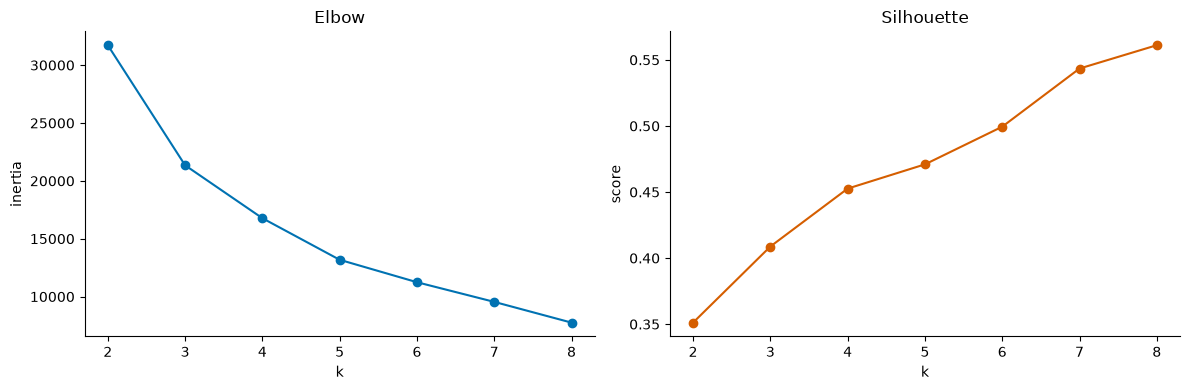

 k  inertia  silhouette
 2    31722        0.35
 3    21348        0.41
 4    16775        0.45
 5    13182        0.47
 6    11244        0.50
 7     9545        0.54
 8     7753        0.56


In [4]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_, sample_size=4000, random_state=RANDOM_STATE))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(ks), inertia, "o-", color="#0072B2"); ax1.set_title("Elbow"); ax1.set_xlabel("k"); ax1.set_ylabel("inertia")
ax2.plot(list(ks), silhouette, "o-", color="#D55E00"); ax2.set_title("Silhouette"); ax2.set_xlabel("k"); ax2.set_ylabel("score")
for a in (ax1, ax2): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(pd.DataFrame({"k": list(ks), "inertia": [round(v) for v in inertia],
                    "silhouette": [round(v, 3) for v in silhouette]}).to_string(index=False))

**k = 4 is used.** The reasoning is stated rather than hidden:

- The silhouette keeps rising as k grows. Three of the six features are yes/no flags, so every extra
  cluster can carve off one more exact combination of them and look "cleaner" on paper. Following
  the silhouette upwards would end with one cluster per combination, which is a lookup table and
  not a segmentation.
- The elbow has no sharp bend. Inertia falls most going to k = 3 and k = 4; from k = 5 on, each
  extra cluster buys less than the one before.
- At k = 4 every cluster is a group a shop owner would recognise and could act on (below). At k = 3
  the business purchases are folded into the everyday computers; at k = 5 the parts split by
  quantity alone into "one" and "several", which is not a different customer need.

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
lines["cluster"] = kmeans.labels_

profile = lines.groupby("cluster").agg(
    purchases      = ("saleId", "size"),
    revenue        = ("lineTotal", "sum"),
    median_price   = ("unitPrice", "median"),
    avg_quantity   = ("quantity", "mean"),
    avg_gpu_tier   = ("gpu_tier", "mean"),
    gaming_grade   = ("gaming_grade", "mean"),
    business_grade = ("business_grade", "mean"),
    whole_system   = ("whole_system", "mean"),
)
display(profile)

,purchases,revenue,median_price,avg_quantity,avg_gpu_tier,gaming_grade,business_grade,whole_system
cluster,,,,,,,,
0,3456,"2,747,333.00",317.50,2.05,0.03,0.14,0.00,0.00
1,1590,"16,141,652.00","5,499.00",1.51,2.21,1.00,0.19,0.87
2,1480,"5,505,794.00","1,858.50",1.41,0.00,0.00,1.00,0.62
3,1413,"7,064,012.00","3,945.00",1.24,0.00,0.00,0.00,1.00


### Naming the segments

K-Means numbers its clusters arbitrarily, and the numbers change if the data or the seed does. So the
names are worked out from each cluster's own figures, never written against a cluster number by hand:

1. the highest average GPU tier is **Gaming & performance**. Workstations land here too: they carry the same RTX 3080/3090 cards, and a buyer paying for that much graphics power wants performance whether the use is games, rendering or design work;
2. of the rest, the most business-grade is **Business & office**;
3. of the rest, the most whole-system is **Everyday computers** (laptops and PCs for personal use and study);
4. the last is **Parts & accessories** (upgrades, repairs and add-ons).

In [6]:
remaining = list(profile.index)
names = {}
for name, column in [("Gaming & performance", "avg_gpu_tier"),
                     ("Business & office", "business_grade"),
                     ("Everyday computers", "whole_system")]:
    pick = profile.loc[remaining, column].idxmax()
    names[pick] = name
    remaining.remove(pick)
names[remaining[0]] = "Parts & accessories"

ORDER = ["Gaming & performance", "Business & office", "Everyday computers", "Parts & accessories"]
COLOURS = {"Gaming & performance": "#D55E00", "Business & office": "#0072B2",
           "Everyday computers": "#009E73", "Parts & accessories": "#CC79A7"}

lines["segment"] = pd.Categorical(lines.cluster.map(names), categories=ORDER, ordered=True)
summary = profile.rename(index=names).loc[ORDER]
summary.insert(1, "share_%", summary.purchases / summary.purchases.sum() * 100)
summary.insert(3, "revenue_%", summary.revenue / summary.revenue.sum() * 100)
summary["avg_spend"] = summary.revenue / summary.purchases
display(summary)

,purchases,share_%,revenue,revenue_%,median_price,avg_quantity,avg_gpu_tier,gaming_grade,business_grade,whole_system,avg_spend
cluster,,,,,,,,,,,
Gaming & performance,1590,20.03,"16,141,652.00",51.31,"5,499.00",1.51,2.21,1.00,0.19,0.87,"10,151.98"
Business & office,1480,18.64,"5,505,794.00",17.50,"1,858.50",1.41,0.00,0.00,1.00,0.62,"3,720.13"
Everyday computers,1413,17.80,"7,064,012.00",22.45,"3,945.00",1.24,0.00,0.00,0.00,1.00,"4,999.30"
Parts & accessories,3456,43.53,"2,747,333.00",8.73,317.50,2.05,0.03,0.14,0.00,0.00,794.95


## What each segment buys

In [7]:
mix = pd.crosstab(lines.subcategory, lines.segment)
for seg in ORDER:
    top = mix[seg].sort_values(ascending=False).head(6)
    top = top[top > 0]
    print(f"{seg:<20} " + ", ".join(f"{sub} ({n})" for sub, n in top.items()))

Gaming & performance Gaming PC (977), Workstation (301), Graphics Card (205), Prebuilt Gaming PCs (107)
Business & office    Business Laptop (335), Office PC (332), Laser Printer (209), Multifunction Printer (203), Premium Laptop (136), Docking Station (71)
Everyday computers   Ultrabook (371), Productivity PC (323), AI PC (281), Consumer Laptop (264), OLED Laptop (113), Premium Laptop (54)
Parts & accessories  Processor (343), Storage (341), Memory (282), Power Supply (251), Cooling (238), Monitor (225)


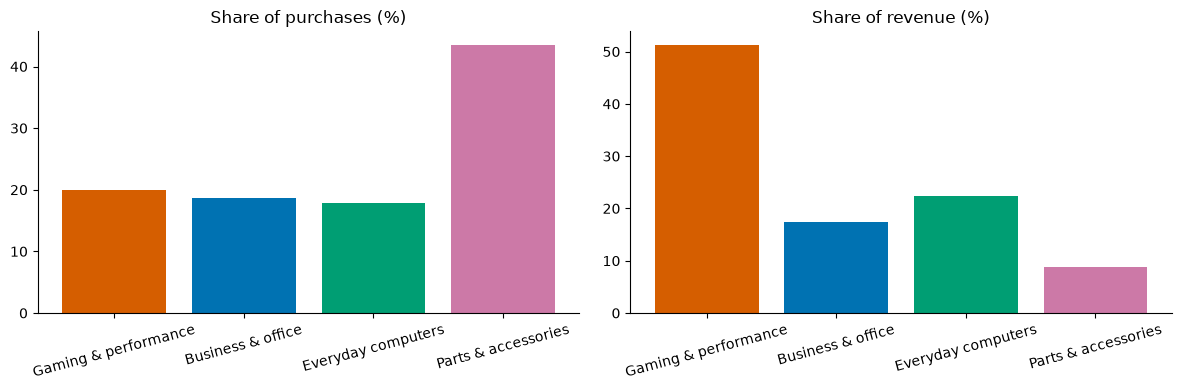

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colours = [COLOURS[s] for s in ORDER]
ax1.bar(ORDER, summary["share_%"], color=colours); ax1.set_title("Share of purchases (%)")
ax2.bar(ORDER, summary["revenue_%"], color=colours); ax2.set_title("Share of revenue (%)")
for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## How the segments change over time

Shares are used rather than totals, because the shop's total takings fall every year. A segment
whose revenue falls more slowly than the shop's is *gaining* share, which is the signal a buyer needs.
2026 covers January to August only.

segment,Gaming & performance,Business & office,Everyday computers,Parts & accessories
year,,,,
2022,49.80,19.30,22.20,8.70
2023,52.30,24.50,14.50,8.80
2024,54.60,14.60,23.70,7.00
2025,51.40,12.00,29.60,6.90
2026,46.10,13.00,25.70,15.30


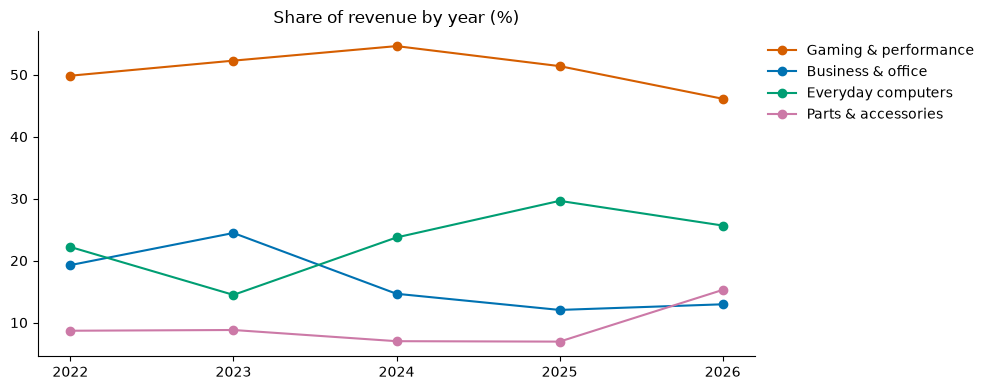

In [9]:
lines["year"] = lines.date.dt.year
yearly = (lines.pivot_table(index="year", columns="segment", values="lineTotal", aggfunc="sum", observed=False)
               .reindex(columns=ORDER))
yearly_share = yearly.div(yearly.sum(axis=1), axis=0) * 100
display(yearly_share.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for seg in ORDER:
    ax.plot(yearly_share.index, yearly_share[seg], "o-", color=COLOURS[seg], label=seg)
ax.set_title("Share of revenue by year (%)"); ax.set_xticks(yearly_share.index)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1)); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Seasonality

Which months each segment over- or under-sells, as an index: 100 means the segment sells its usual
share of the year in that month, 130 means 30% above. This is the table a marketing calendar is built from.

segment,Gaming & performance,Business & office,Everyday computers,Parts & accessories
month,,,,
1,82,79,94,79
2,75,88,85,88
3,80,93,82,91
4,80,77,89,83
5,112,84,105,95
6,103,100,87,98
7,106,108,94,92
8,106,106,92,107
9,94,112,106,104


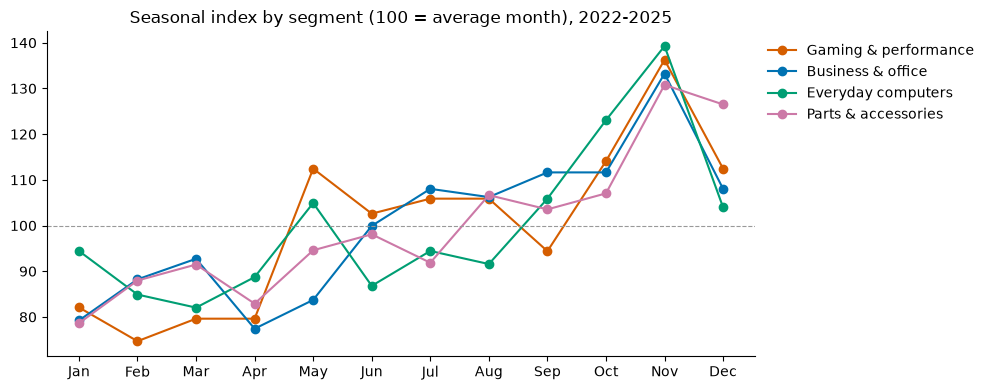

Gaming & performance busiest 11 (136), quietest  2 (75)
Business & office    busiest 11 (133), quietest  4 (77)
Everyday computers   busiest 11 (139), quietest  3 (82)
Parts & accessories  busiest 11 (131), quietest  1 (79)


In [10]:
lines["month"] = lines.date.dt.month
full_years = lines[lines.year <= 2025]                     # 2026 has no Sep-Dec yet
monthly = full_years.pivot_table(index="month", columns="segment", values="saleId",
                                 aggfunc="count", observed=False).reindex(columns=ORDER)
season_index = monthly.div(monthly.mean()) * 100
display(season_index.round(0).astype(int))

fig, ax = plt.subplots(figsize=(10, 4))
for seg in ORDER:
    ax.plot(season_index.index, season_index[seg], "o-", color=COLOURS[seg], label=seg)
ax.axhline(100, color="#999", lw=0.8, ls="--")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Seasonal index by segment (100 = average month), 2022-2025")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1)); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

for seg in ORDER:
    s = season_index[seg]
    print(f"{seg:<20} busiest {s.idxmax():>2} ({s.max():.0f}), quietest {s.idxmin():>2} ({s.min():.0f})")

## Assigning new purchases

A fitted K-Means model is also a classifier: a new purchase belongs to the segment whose centre it
lies nearest. That is how the website's future orders are placed into these segments. The same six
features are built from the order line, scaled with the same scaler, and `kmeans.predict` names the
segment. Four made-up purchases show it working:

In [11]:
examples = pd.DataFrame([
    {"what": "Gaming rig with an RTX 3080, RM 6,500",    "price": 6500, "quantity": 1, "gpu_tier": 3, "gaming_grade": 1, "business_grade": 0, "whole_system": 1},
    {"what": "Five office PCs, RM 1,900 each",           "price": 1900, "quantity": 5, "gpu_tier": 0, "gaming_grade": 0, "business_grade": 1, "whole_system": 1},
    {"what": "ASUS Zenbook ultrabook, RM 4,100",         "price": 4100, "quantity": 1, "gpu_tier": 0, "gaming_grade": 0, "business_grade": 0, "whole_system": 1},
    {"what": "Two 16 GB RAM sticks, RM 280 each",        "price":  280, "quantity": 2, "gpu_tier": 0, "gaming_grade": 0, "business_grade": 0, "whole_system": 0},
])
features = examples[FEATURES].assign(price=np.log10(examples.price), quantity=np.log2(examples.quantity))
examples["segment"] = [names[c] for c in kmeans.predict(scaler.transform(features))]
display(examples[["what", "segment"]])

,what,segment
0,"Gaming rig with an RTX 3080, RM 6,500",Gaming & performance
1,"Five office PCs, RM 1,900 each",Business & office
2,"ASUS Zenbook ultrabook, RM 4,100",Everyday computers
3,"Two 16 GB RAM sticks, RM 280 each",Parts & accessories


## Saving the assignments

One row per receipt with its segment, for the report and for the staff console. Revenue and selling
price only: no cost, margin or customer columns, in line with the data agreement.

In [12]:
out = lines[["saleId", "date", "sku", "itemName", "category", "subcategory", "quantity",
             "unitPrice", "lineTotal", "gpu_tier", "gaming_grade", "business_grade",
             "whole_system", "segment"]]
out.to_csv("data/processed/purchase_segments.csv", index=False)

centres = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
centres["segment"] = [names[i] for i in range(K)]
centres["price"] = 10 ** centres.price          # back from log scale, for reading
centres["quantity"] = 2 ** centres.quantity
centres[FEATURES] = centres[FEATURES].round(2) + 0.0   # + 0.0 turns -0.00 into 0.00
display(centres.set_index("segment").loc[ORDER])
print(f"wrote data/processed/purchase_segments.csv ({len(out):,} rows)")

,price,quantity,gpu_tier,gaming_grade,business_grade,whole_system
segment,,,,,,
Gaming & performance,"5,979.12",1.37,2.21,1.00,0.19,0.87
Business & office,"1,975.35",1.29,0.00,0.00,1.00,0.62
Everyday computers,"3,980.69",1.17,0.00,0.00,0.00,1.00
Parts & accessories,272.06,1.66,0.03,0.14,0.00,0.00


wrote data/processed/purchase_segments.csv (7,939 rows)


## What this run says

1. **The purchases split four ways**, and every group is one a shop owner would recognise:

   | Segment | Purchases | Revenue | Average spend |
   |---|---|---|---|
   | Gaming & performance | 20% | 51% | about RM 10,150 |
   | Everyday computers | 18% | 22% | about RM 5,000 |
   | Business & office | 19% | 18% | about RM 3,700 |
   | Parts & accessories | 44% | 9% | about RM 800 |

2. **Gaming & performance is where the money is.** It brings in half the revenue from a fifth of the
   purchases, so stock-outs and pricing mistakes cost the most here.
3. **Parts & accessories is the opposite:** the most purchases and the least revenue. Its value is
   footfall and add-on sales: a buyer who comes in for RAM is a buyer who can be shown a rig.
4. **The mix is moving.** Everyday computers grew from 22% of revenue in 2022 to 30% in 2025, while
   Business & office fell from a 2023 high of 25% to 12%. In 2026 parts and accessories double their
   share to 15%. That coincides with the January 2026 range change, and 2026 covers January to August
   only, so it is a pattern to watch rather than a conclusion.
5. **Every segment peaks in November** (index 131-139) and is quietest from January to April. Two
   segments start early: Everyday computers is already above average in September and October
   (106 and 123), and Business & office in September (112). Parts & accessories stays high into December (127).

### What the shop can do with it

| Segment | When | Action |
|---|---|---|
| Gaming & performance | November | Lead the year-end campaign with rigs and graphics cards; it is half the revenue |
| Everyday computers | September-October | Laptop and productivity-PC promotions before the November peak, possibly linked to the academic intake |
| Business & office | September-November | Quantity pricing on office PCs, business laptops and printers; April is its quietest month |
| Parts & accessories | All year, December | Bundle with rigs and laptops at checkout; upgrade offers in December |

### Limits, stated for the report

- These are **purchase** segments. A receipt says what was bought, not who bought it, so a student who
  buys a gaming rig is counted as a gaming purchase.
- `gaming_grade` and `business_grade` are read from product names and sub-categories. That is a judgement
  about the product, written out in full above, not a fact about the buyer.
- Workstations sit in Gaming & performance because of their graphics cards. That is defensible
  (same hardware, same price), but it means the segment is "high performance", not "games only".

### Next

- **Check against real customers.** Website accounts carry a Student, Gamer or Enterprise role from
  sign-up. Once the beta testers have bought, `kmeans.predict` on their orders against their own
  role shows how often a purchase segment matches the person, which is the accuracy figure this
  notebook cannot produce on its own.
- **Forecast each segment separately**, joining this notebook to `02_forecasting.ipynb`. Gaming &
  performance and Parts & accessories clearly do not move together.